In [5]:
import pandas as pd 
import os 
import numpy as np 
from sklearn.feature_selection import SelectKBest, f_classif

In [6]:
a=os.chdir("C:\\Users\\lenovo\\Desktop\\ml_miniproject")
os.getcwd()
a=os.listdir()
print(a)

['adaboost.pdf', "alzhiemer's.pdf", 'arthritis.pdf', 'baseline_lipidomics.csv', 'decision_tree.pdf', 'Feature_Selection_vs_All_Features_ROCAUC.png', 'intervertebral_degeneration.pdf', 'lipidomics.csv', 'lipodomics.pdf', 'LNEG_LPOS_Combined_ROCAUC.png', 'LogisticRegression_lipidomics_validation.csv', 'MTX_Lipidomics_Dataset1.csv', 'ngs miniproject', 'pheno_total.csv', 'rna seq.pdf', 'SHAP_KNN_summary.png', 'shreya_miniproject_workflow.docx', 'snp_tb.pdf', 'svm.pdf', 'tnbc.pdf']


In [4]:
k=pd.read_csv("baseline_lipidomics.csv")
k

,sample_name,LNEG_V1,LNEG_V2,LNEG_V3,LNEG_V4,LNEG_V5,LNEG_V6,LNEG_V7,LNEG_V8,LNEG_V9,...,LPOS_V2298,LPOS_V2299,LPOS_V2300,LPOS_V2301,LPOS_V2302,LPOS_V2303,LPOS_V2304,LPOS_V2305,LPOS_V2306,MTX_response
0,80,1463695.663,101199.39340,154750.520200,1.206652e+06,70399.06040,57328.11865,179675.40820,130509.54850,3.215415e+06,...,116060.914700,58736.37552,16735.80681,67444.320700,67251.969720,30907.009930,17198.699130,15984.298360,6769.319070,good-responder
1,27,1510259.669,13137.90538,11783.716980,3.063509e+05,21247.40909,57066.81680,46604.00189,47545.45480,3.863774e+05,...,8450.494636,76597.15108,36575.12370,109962.988500,112472.992300,55681.439950,25292.268030,29187.492470,14161.418490,good-responder
2,78,1324539.447,55892.95302,55576.292670,7.145204e+05,195478.61140,44131.23167,95807.79417,104786.65350,1.915835e+06,...,344300.927500,180613.92770,70122.41435,41172.405980,41547.237370,15082.357700,36057.064820,40200.709100,16827.817630,good-responder
3,75,1401576.360,46181.36508,37165.870080,5.208852e+05,40944.06055,46148.18832,80530.59959,67056.48760,8.861427e+05,...,196158.308800,101023.29510,39489.04128,62651.142940,63125.258800,31749.186570,39275.893640,41576.474480,22892.124250,good-responder
4,101,1783749.727,11276.45889,5734.502042,3.590573e+05,135609.37760,51791.51389,55785.44480,74565.45636,3.476121e+05,...,302057.762400,157644.98650,56567.14523,11604.614010,11428.781250,6337.461366,7476.993009,7235.022575,2389.557595,good-responder
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,18,1737282.568,51705.87110,38756.117900,6.407241e+05,56537.95048,51071.14492,95072.86345,100456.08940,1.159223e+06,...,193733.867800,96885.81951,40152.27905,27453.207410,38134.250520,17752.369090,27224.546340,38722.405140,18947.469550,non-responder
96,41,2599536.927,38715.35831,42828.807780,5.724503e+05,167880.76270,39301.78753,82620.34425,117285.28460,1.359721e+06,...,432756.990200,227604.13370,94216.83429,1238.336861,577.318296,725.456458,309.455870,1263.575273,393.734486,good-responder
97,74,1957215.238,72757.14897,45173.545290,6.437543e+05,12890.53949,42011.14287,93272.45595,96023.58069,1.307056e+06,...,133784.017300,67087.54351,14298.70525,208795.511200,221445.319100,104293.105900,87512.268930,96140.434070,47723.683530,non-responder
98,47,2346569.602,75151.86025,114034.398600,9.364080e+05,36151.39616,60252.48889,134212.88270,134708.71890,2.717917e+06,...,221298.383600,119029.23000,40570.18016,74232.634290,79191.664400,35896.084270,37003.504740,40448.802480,13912.595800,non-responder


In [5]:
import pandas as pd

# Lipid features
X = k.iloc[:, 1:-1]

# MTX response
y = (k.iloc[:, -1] == "good-responder").astype(int)

print(X.shape)
print(y.shape)

(100, 3366)
(100,)


In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=123,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(80, 3366)
(20, 3366)


In [7]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

lr = LogisticRegression(
    max_iter=2000,
    solver="liblinear"
)

lr.fit(X_train_s, y_train)

y_pred_lr = lr.predict(X_test_s)

print("Logistic Regression Accuracy:",
      accuracy_score(y_test, y_pred_lr))

print(confusion_matrix(y_test, y_pred_lr))

print(classification_report(y_test, y_pred_lr))

Logistic Regression Accuracy: 0.55
[[5 5]
 [4 6]]
              precision    recall  f1-score   support

           0       0.56      0.50      0.53        10
           1       0.55      0.60      0.57        10

    accuracy                           0.55        20
   macro avg       0.55      0.55      0.55        20
weighted avg       0.55      0.55      0.55        20



In [9]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train_s, y_train)

y_pred_knn = knn.predict(X_test_s)

print("KNN Accuracy:",
      accuracy_score(y_test, y_pred_knn))

print(confusion_matrix(y_test, y_pred_knn))

print(classification_report(y_test, y_pred_knn))

KNN Accuracy: 0.6
[[6 4]
 [4 6]]
              precision    recall  f1-score   support

           0       0.60      0.60      0.60        10
           1       0.60      0.60      0.60        10

    accuracy                           0.60        20
   macro avg       0.60      0.60      0.60        20
weighted avg       0.60      0.60      0.60        20



In [10]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(
    random_state=123
)

dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)

print("Decision Tree Accuracy:",
      accuracy_score(y_test, y_pred_dt))

print(confusion_matrix(y_test, y_pred_dt))

print(classification_report(y_test, y_pred_dt))

Decision Tree Accuracy: 0.5
[[3 7]
 [3 7]]
              precision    recall  f1-score   support

           0       0.50      0.30      0.38        10
           1       0.50      0.70      0.58        10

    accuracy                           0.50        20
   macro avg       0.50      0.50      0.48        20
weighted avg       0.50      0.50      0.48        20



In [11]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=123
)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
 
print("Random Forest Accuracy:",
      accuracy_score(y_test, y_pred_rf))

print(confusion_matrix(y_test, y_pred_rf))

print(classification_report(y_test, y_pred_rf))

Random Forest Accuracy: 0.65
[[6 4]
 [3 7]]
              precision    recall  f1-score   support

           0       0.67      0.60      0.63        10
           1       0.64      0.70      0.67        10

    accuracy                           0.65        20
   macro avg       0.65      0.65      0.65        20
weighted avg       0.65      0.65      0.65        20



In [12]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import numpy as np

In [14]:
#LR
pipeline_lr = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000))
])
param_grid_lr = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__solver": ["liblinear", "lbfgs"]
}
inner_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=123
)
outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=456
)
grid_lr = GridSearchCV(
    estimator=pipeline_lr,
    param_grid=param_grid_lr,
    cv=inner_cv,
    scoring="accuracy"
)

scores_lr = cross_val_score(
    grid_lr,
    X,
    y,
    cv=outer_cv,
    scoring="accuracy"
)
print("Outer CV scores:", scores_lr)
print("Mean accuracy:", scores_lr.mean())
print("Standard deviation:", scores_lr.std())

Outer CV scores: [0.4  0.6  0.55 0.5  0.45]
Mean accuracy: 0.5
Standard deviation: 0.07071067811865475


In [15]:
#LR
pipeline_lr = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000))
])
param_grid_lr = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__solver": ["liblinear", "lbfgs"]
}
inner_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=123
)
outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=456
)
grid_lr = GridSearchCV(
    estimator=pipeline_lr,
    param_grid=param_grid_lr,
    cv=inner_cv,
    scoring="roc_auc"
)

scores_lr = cross_val_score(
    grid_lr,
    X,
    y,
    cv=outer_cv,
    scoring="roc_auc"
)
print("Outer CV scores:", scores_lr)
print("Mean ROC_AUC:", scores_lr.mean())
print("Standard deviation:", scores_lr.std())

Outer CV scores: [0.47 0.61 0.59 0.55 0.47]
Mean ROC_AUC: 0.5379999999999999
Standard deviation: 0.0587877538267963


In [16]:
#knn nested cv 
pipeline_knn = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier())
])
param_grid_knn = {
    "model__n_neighbors": [3, 5, 7, 9],
    "model__weights": ["uniform", "distance"]
}
inner_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=123
)
outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=456
)
#nested cv 
grid_knn = GridSearchCV(
    estimator=pipeline_knn,
    param_grid=param_grid_knn,
    cv=inner_cv,
    scoring="accuracy"
)

scores_knn = cross_val_score(
    grid_knn,
    X,
    y,
    cv=outer_cv,
    scoring="accuracy"
)
print("Outer CV scores:", scores_knn)
print("Mean accuracy:", scores_knn.mean())
print("Standard deviation:", scores_knn.std())

Outer CV scores: [0.6  0.4  0.55 0.7  0.45]
Mean accuracy: 0.54
Standard deviation: 0.10677078252031309


In [17]:
#knn nested cv 
pipeline_knn = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier())
])
param_grid_knn = {
    "model__n_neighbors": [3, 5, 7, 9],
    "model__weights": ["uniform", "distance"]
}
inner_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=123
)
outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=456
)
#nested cv 
grid_knn = GridSearchCV(
    estimator=pipeline_knn,
    param_grid=param_grid_knn,
    cv=inner_cv,
    scoring="roc_auc"
)

scores_knn = cross_val_score(
    grid_knn,
    X,
    y,
    cv=outer_cv,
    scoring="roc_auc"
)
print("Outer CV scores:", scores_knn)
print("Mean ROC_AUC:", scores_knn.mean())
print("Standard deviation:", scores_knn.std())

Outer CV scores: [0.62 0.49 0.62 0.73 0.41]
Mean ROC_AUC: 0.5740000000000001
Standard deviation: 0.11182128598795489


In [18]:
#decision tree nested cv 
pipeline_dt = Pipeline([
    ("model", DecisionTreeClassifier(random_state=123))
])
param_grid_dt = {
    "model__max_depth": [None, 3, 5, 10],
    "model__min_samples_split": [2, 5, 10]
}
inner_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=123
)
outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=456
)
#nested cv 
grid_dt = GridSearchCV(
    estimator=pipeline_dt,
    param_grid=param_grid_dt,
    cv=inner_cv,
    scoring="accuracy"
)

scores_dt = cross_val_score(
    grid_dt,
    X,
    y,
    cv=outer_cv,
    scoring="accuracy"
)
print("Outer CV scores:", scores_dt)
print("Mean accuracy:", scores_dt.mean())
print("Standard deviation:", scores_dt.std())

Outer CV scores: [0.6  0.5  0.6  0.45 0.35]
Mean accuracy: 0.5000000000000001
Standard deviation: 0.09486832980505137


In [19]:
#decision tree nested cv 
pipeline_dt = Pipeline([
    ("model", DecisionTreeClassifier(random_state=123))
])
param_grid_dt = {
    "model__max_depth": [None, 3, 5, 10],
    "model__min_samples_split": [2, 5, 10]
}
inner_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=123
)
outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=456
)
#nested cv 
grid_dt = GridSearchCV(
    estimator=pipeline_dt,
    param_grid=param_grid_dt,
    cv=inner_cv,
    scoring="roc_auc"
)

scores_dt = cross_val_score(
    grid_dt,
    X,
    y,
    cv=outer_cv,
    scoring="roc_auc"
)
print("Outer CV scores:", scores_dt)
print("Mean ROC_AUC:", scores_dt.mean())
print("Standard deviation:", scores_dt.std())

Outer CV scores: [0.6   0.5   0.6   0.47  0.365]
Mean ROC_AUC: 0.507
Standard deviation: 0.08818163074019443


In [20]:
#RF
pipeline_rf = Pipeline([
    ("model", RandomForestClassifier(random_state=123))
])
param_grid_rf = {
    "model__n_estimators": [100],
    "model__max_depth": [None, 5],
    "model__min_samples_split": [2,10]
}
inner_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=123
)
outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=456
)
#nested cv 
grid_rf = GridSearchCV(
    estimator=pipeline_rf,
    param_grid=param_grid_rf,
    cv=inner_cv,
    scoring="accuracy",
    n_jobs=-1
)

scores_rf = cross_val_score(
    grid_rf,
    X,
    y,
    cv=outer_cv,
    scoring="accuracy",
    n_jobs=-1
)
print("Outer CV scores:", scores_rf)
print("Mean accuracy:", scores_rf.mean())
print("Standard deviation:", scores_rf.std())

Outer CV scores: [0.6  0.55 0.5  0.5  0.45]
Mean accuracy: 0.52
Standard deviation: 0.05099019513592784


In [21]:
#RF
pipeline_rf = Pipeline([
    ("model", RandomForestClassifier(random_state=123))
])
param_grid_rf = {
    "model__n_estimators": [100],
    "model__max_depth": [None, 5],
    "model__min_samples_split": [2,10]
}
inner_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=123
)
outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=456
)
#nested cv 
grid_rf = GridSearchCV(
    estimator=pipeline_rf,
    param_grid=param_grid_rf,
    cv=inner_cv,
    scoring="roc_auc",
    n_jobs=-1
)

scores_rf = cross_val_score(
    grid_rf,
    X,
    y,
    cv=outer_cv,
    scoring="roc_auc",
    n_jobs=-1
)
print("Outer CV scores:", scores_rf)
print("Mean ROC_AUC:", scores_rf.mean())
print("Standard deviation:", scores_rf.std())

Outer CV scores: [0.6   0.54  0.495 0.62  0.38 ]
Mean ROC_AUC: 0.527
Standard deviation: 0.08576712656956627


In [22]:
#SVM 
from sklearn.svm import SVC

pipeline_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC())
])

param_grid_svm = {
    "model__C": [0.1, 1, 10],
    "model__kernel": ["linear", "rbf"]
}

inner_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=123
)

outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=456
)

grid_svm = GridSearchCV(
    estimator=pipeline_svm,
    param_grid=param_grid_svm,
    cv=inner_cv,
    scoring="accuracy",
    n_jobs=-1
)

scores_svm = cross_val_score(
    grid_svm,
    X,
    y,
    cv=outer_cv,
    scoring="accuracy",
    n_jobs=-1
)

print("Outer CV scores:", scores_svm)
print("Mean accuracy:", scores_svm.mean())
print("Standard deviation:", scores_svm.std())

Outer CV scores: [0.4  0.55 0.55 0.55 0.4 ]
Mean accuracy: 0.48999999999999994
Standard deviation: 0.07348469228349534


In [23]:
#SVM 
from sklearn.svm import SVC

pipeline_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC())
])

param_grid_svm = {
    "model__C": [0.1, 1, 10],
    "model__kernel": ["linear", "rbf"]
}

inner_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=123
)

outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=456
)

grid_svm = GridSearchCV(
    estimator=pipeline_svm,
    param_grid=param_grid_svm,
    cv=inner_cv,
    scoring="roc_auc",
    n_jobs=-1
)

scores_svm = cross_val_score(
    grid_svm,
    X,
    y,
    cv=outer_cv,
    scoring="roc_auc",
    n_jobs=-1
)

print("Outer CV scores:", scores_svm)
print("Mean ROC_AUC:", scores_svm.mean())
print("Standard deviation:", scores_svm.std())

Outer CV scores: [0.45 0.51 0.56 0.56 0.37]
Mean ROC_AUC: 0.49000000000000005
Standard deviation: 0.07238784428341542


In [24]:
#ELASTIC LR
from sklearn.linear_model import LogisticRegression

pipeline_en = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        penalty="elasticnet",
        solver="saga",
        max_iter=300,
        random_state=123
    ))
])
param_grid_en = {
    "model__C": [0.1, 1, 10],
    "model__l1_ratio": [0.2, 0.5, 0.8]
}
inner_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=123
)
outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=456
)
#nested cv 
grid_en = GridSearchCV(
    estimator=pipeline_en,
    param_grid=param_grid_en,
    cv=inner_cv,
    scoring="accuracy",
    n_jobs=-1
)

scores_en = cross_val_score(
    grid_en,
    X,
    y,
    cv=outer_cv,
    scoring="accuracy",
    n_jobs=-1
)
print("Outer CV scores:", scores_en)
print("Mean accuracy:", scores_en.mean())
print("Standard deviation:", scores_en.std())

Outer CV scores: [0.55 0.6  0.55 0.4  0.45]
Mean accuracy: 0.51
Standard deviation: 0.07348469228349534


In [25]:
#ELASTIC LR
from sklearn.linear_model import LogisticRegression

pipeline_en = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        penalty="elasticnet",
        solver="saga",
        max_iter=300,
        random_state=123
    ))
])
param_grid_en = {
    "model__C": [0.1, 1, 10],
    "model__l1_ratio": [0.2, 0.5, 0.8]
}
inner_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=123
)
outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=456
)
#nested cv 
grid_en = GridSearchCV(
    estimator=pipeline_en,
    param_grid=param_grid_en,
    cv=inner_cv,
    scoring="roc_auc",
    n_jobs=-1
)

scores_en = cross_val_score(
    grid_en,
    X,
    y,
    cv=outer_cv,
    scoring="roc_auc",
    n_jobs=-1
)
print("Outer CV scores:", scores_en)
print("Mean ROC_AUC:", scores_en.mean())
print("Standard deviation:", scores_en.std())

Outer CV scores: [0.49 0.65 0.55 0.54 0.48]
Mean ROC_AUC: 0.542
Standard deviation: 0.06046486583132391


In [47]:
#PERMUTATION TEST ON KNN
from sklearn.model_selection import permutation_test_score
import numpy as np
import matplotlib.pyplot as plt

score, permutation_scores, pvalue = permutation_test_score(
    grid_knn,
    X,
    y,
    scoring="roc_auc",
    cv=outer_cv,
    n_permutations=100,
    n_jobs=-1,
    random_state=123
)

print("Observed ROC-AUC:", score)
print("Permutation p-value:", pvalue)

Observed ROC-AUC: 0.5740000000000001
Permutation p-value: 0.13861386138613863


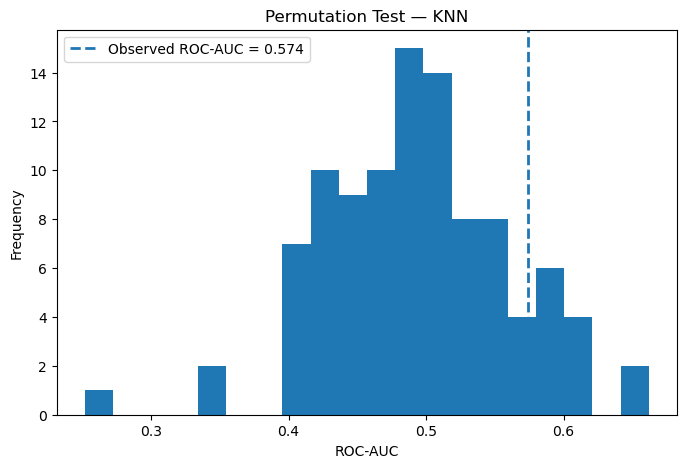

In [48]:
plt.figure(figsize=(8,5))

plt.hist(permutation_scores, bins=20)

plt.axvline(
    score,
    linestyle="--",
    linewidth=2,
    label=f"Observed ROC-AUC = {score:.3f}"
)

plt.xlabel("ROC-AUC")
plt.ylabel("Frequency")
plt.title("Permutation Test — KNN")
plt.legend()

plt.show()

In [29]:
pip install shap 


   ---------------------------------------- 0/2 [slicer]
   ---------------------------------------- 0/2 [slicer]
   ---------------------------------------- 0/2 [slicer]
   ---------------------------------------- 0/2 [slicer]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
 

In [30]:
import shap

In [31]:
grid_knn.fit(X, y)

best_knn = grid_knn.best_estimator_

In [33]:
# SHAP ANALYSIS FOR KNN

import shap
import numpy as np
import matplotlib.pyplot as plt

# Fit the tuned KNN model
grid_knn.fit(X, y)

# Get the best pipeline
best_knn = grid_knn.best_estimator_

# Separate scaler and KNN model
scaler = best_knn.named_steps["scaler"]
knn_model = best_knn.named_steps["model"]

# Scale all lipidomic data
X_scaled = scaler.transform(X)

# Use a small subset of patients for SHAP
X_background = X_scaled[:10]
X_explain = X_scaled[:10]

# Create SHAP explainer for the actual KNN model
explainer = shap.KernelExplainer(
    knn_model.predict_proba,
    X_background
)

# Calculate SHAP values
shap_values = explainer.shap_values(
    X_explain,
    nsamples=50
)

# Check the output
print("SHAP calculation completed!")
print("Type:", type(shap_values))
print("Shape:", np.array(shap_values).shape)

  0%|          | 0/10 [00:00<?, ?it/s]

C:\Users\lenovo\anaconda3\Lib\site-packages\shap\explainers\_kernel.py:765: UserWarning: Linear regression equation is singular, a least squares solutions is used instead.
To avoid this situation and get a regular matrix do one of the following:
1) turn up the number of samples,
2) turn up the L1 regularization with num_features(N) where N is less than the number of samples,
3) group features together to reduce the number of inputs that need to be explained.
  warnings.warn(


SHAP calculation completed!
Type: <class 'numpy.ndarray'>
Shape: (10, 3366, 2)


In [35]:
# Rank features by mean absolute SHAP value

mean_abs_shap = np.mean(
    np.abs(shap_values_class1),
    axis=0
)

shap_importance = pd.DataFrame({
    "Feature": X.columns,
    "Mean_Absolute_SHAP": mean_abs_shap
})

shap_importance = shap_importance.sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
)

print(shap_importance.head(20))

         Feature  Mean_Absolute_SHAP
1489   LPOS_V430            0.050317
1612   LPOS_V553            0.047673
2062  LPOS_V1003            0.026847
2        LNEG_V3            0.026324
1186   LPOS_V127            0.022883
53      LNEG_V54            0.016954
2168  LPOS_V1109            0.016332
3288  LPOS_V2229            0.016229
184    LNEG_V185            0.015975
1351   LPOS_V292            0.011214
226    LNEG_V227            0.008760
3336  LPOS_V2277            0.008568
2781  LPOS_V1722            0.008320
238    LNEG_V239            0.008206
1131    LPOS_V72            0.008186
936    LNEG_V937            0.008121
2366  LPOS_V1307            0.007166
2424  LPOS_V1365            0.007147
91      LNEG_V92            0.006852
1399   LPOS_V340            0.006271


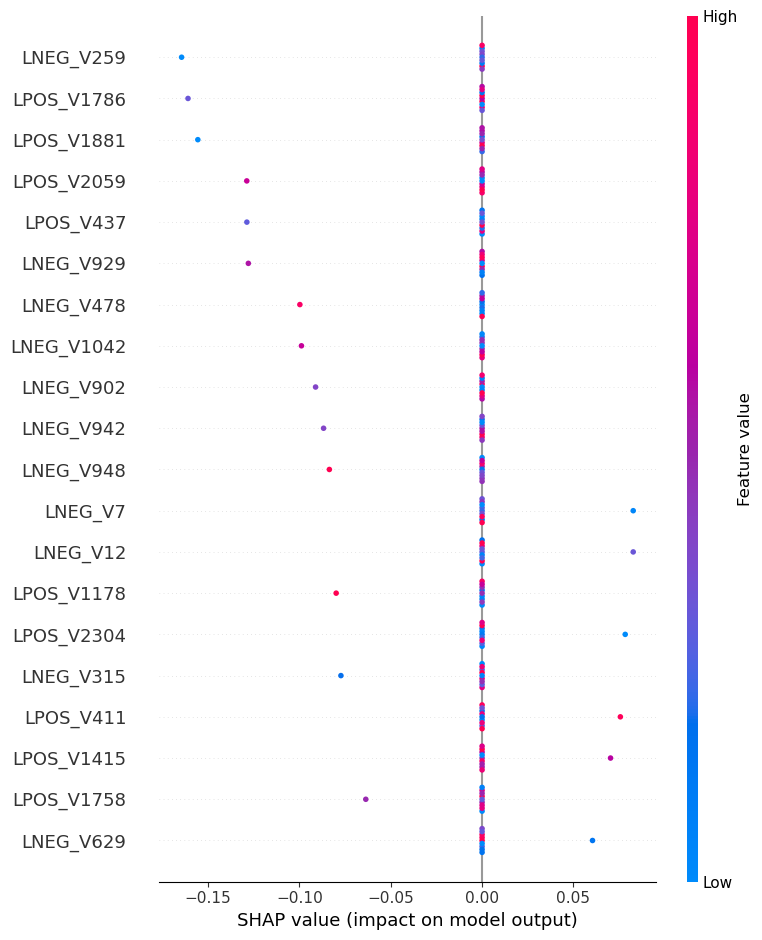

In [52]:
plt.figure(figsize=(10, 8))

shap.summary_plot(
    shap_values_class1,
    X_explain,
    feature_names=X.columns,
    max_display=20,
    show=False
)

plt.savefig(
    "SHAP_KNN_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [37]:
# ============================================
# NOVELTY ANALYSIS: LNEG vs LPOS vs COMBINED
# ============================================

import numpy as np
from sklearn.model_selection import GridSearchCV, cross_val_score

# Separate the lipidomic features by ionization mode
X_lneg = X.loc[:, X.columns.str.startswith("LNEG_")]
X_lpos = X.loc[:, X.columns.str.startswith("LPOS_")]
X_combined = X

print("LNEG features:", X_lneg.shape[1])
print("LPOS features:", X_lpos.shape[1])
print("Combined features:", X_combined.shape[1])


# Function for nested CV using KNN
def run_nested_knn(X_data, y_data):

    grid = GridSearchCV(
        estimator=pipeline_knn,
        param_grid=param_grid_knn,
        cv=inner_cv,
        scoring="roc_auc",
        n_jobs=-1
    )

    scores = cross_val_score(
        grid,
        X_data,
        y_data,
        cv=outer_cv,
        scoring="roc_auc",
        n_jobs=-1
    )

    return scores


# Run for each feature set
scores_lneg = run_nested_knn(X_lneg, y)
scores_lpos = run_nested_knn(X_lpos, y)
scores_combined = run_nested_knn(X_combined, y)


# Print results
print("\nLNEG ROC-AUC scores:", scores_lneg)
print("LNEG Mean ROC-AUC:", scores_lneg.mean())
print("LNEG SD:", scores_lneg.std())

print("\nLPOS ROC-AUC scores:", scores_lpos)
print("LPOS Mean ROC-AUC:", scores_lpos.mean())
print("LPOS SD:", scores_lpos.std())

print("\nCOMBINED ROC-AUC scores:", scores_combined)
print("COMBINED Mean ROC-AUC:", scores_combined.mean())
print("COMBINED SD:", scores_combined.std())

LNEG features: 1060
LPOS features: 2306
Combined features: 3366

LNEG ROC-AUC scores: [0.55 0.36 0.41 0.69 0.51]
LNEG Mean ROC-AUC: 0.5040000000000001
LNEG SD: 0.11516944039110376

LPOS ROC-AUC scores: [0.64  0.485 0.515 0.67  0.485]
LPOS Mean ROC-AUC: 0.5589999999999999
LPOS SD: 0.07971198153351855

COMBINED ROC-AUC scores: [0.62 0.49 0.62 0.73 0.41]
COMBINED Mean ROC-AUC: 0.5740000000000001
COMBINED SD: 0.11182128598795489


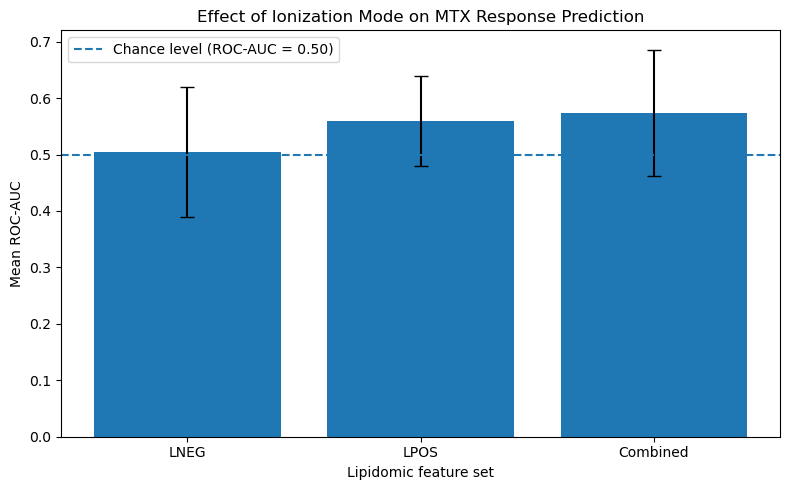

In [38]:
import matplotlib.pyplot as plt
import numpy as np

labels = ["LNEG", "LPOS", "Combined"]
means = [
    scores_lneg.mean(),
    scores_lpos.mean(),
    scores_combined.mean()
]

errors = [
    scores_lneg.std(),
    scores_lpos.std(),
    scores_combined.std()
]

plt.figure(figsize=(8, 5))

plt.bar(labels, means, yerr=errors, capsize=5)

plt.axhline(
    0.5,
    linestyle="--",
    linewidth=1.5,
    label="Chance level (ROC-AUC = 0.50)"
)

plt.ylabel("Mean ROC-AUC")
plt.xlabel("Lipidomic feature set")
plt.title("Effect of Ionization Mode on MTX Response Prediction")
plt.legend()

plt.tight_layout()

plt.savefig(
    "LNEG_LPOS_Combined_ROCAUC.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [46]:

# ============================================================
# FEATURE SELECTION + 6 MODELS
# ============================================================

# We will test these numbers of selected features
k_values = [50, 100, 250, 500]

# ------------------------------------------------------------
# 1. LOGISTIC REGRESSION
# ------------------------------------------------------------

pipe_lr_fs = Pipeline([
    ("selector", SelectKBest(score_func=f_classif)),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000))
])

grid_lr_fs = {
    "selector__k": k_values,
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__solver": ["liblinear", "lbfgs"]
}

# ------------------------------------------------------------
# 2. KNN
# ------------------------------------------------------------

pipe_knn_fs = Pipeline([
    ("selector", SelectKBest(score_func=f_classif)),
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier())
])

grid_knn_fs = {
    "selector__k": k_values,
    "model__n_neighbors": [3, 5, 7, 9],
    "model__weights": ["uniform", "distance"]
}

# ------------------------------------------------------------
# 3. DECISION TREE
# ------------------------------------------------------------

pipe_dt_fs = Pipeline([
    ("selector", SelectKBest(score_func=f_classif)),
    ("model", DecisionTreeClassifier(random_state=123))
])

grid_dt_fs = {
    "selector__k": k_values,
    "model__max_depth": [None, 3, 5, 10],
    "model__min_samples_split": [2, 5, 10]
}

# ------------------------------------------------------------
# 4. RANDOM FOREST
# ------------------------------------------------------------

pipe_rf_fs = Pipeline([
    ("selector", SelectKBest(score_func=f_classif)),
    ("model", RandomForestClassifier(random_state=123))
])

grid_rf_fs = {
    "selector__k": k_values,
    "model__n_estimators": [100],
    "model__max_depth": [None, 5],
    "model__min_samples_split": [2, 10]
}

# ------------------------------------------------------------
# 5. SVM
# ------------------------------------------------------------

pipe_svm_fs = Pipeline([
    ("selector", SelectKBest(score_func=f_classif)),
    ("scaler", StandardScaler()),
    ("model", SVC(probability=True))
])

grid_svm_fs = {
    "selector__k": k_values,
    "model__C": [0.1, 1, 10],
    "model__kernel": ["linear", "rbf"]
}

# ------------------------------------------------------------
# 6. ELASTIC-NET LOGISTIC REGRESSION
# ------------------------------------------------------------

pipe_en_fs = Pipeline([
    ("selector", SelectKBest(score_func=f_classif)),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        penalty="elasticnet",
        solver="saga",
        max_iter=300,
        random_state=123
    ))
])

grid_en_fs = {
    "selector__k": k_values,
    "model__C": [0.1, 1, 10],
    "model__l1_ratio": [0.2, 0.5, 0.8]
}

# ============================================================
# FUNCTION FOR NESTED CV
# ============================================================

def run_feature_selection_nested_cv(pipeline, param_grid, name):

    grid = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        cv=inner_cv,
        scoring="roc_auc",
        n_jobs=-1
    )

    scores = cross_val_score(
        grid,
        X,
        y,
        cv=outer_cv,
        scoring="roc_auc",
        n_jobs=-1
    )

    print("\n" + "="*50)
    print(name)
    print("="*50)
    print("Outer ROC-AUC scores:", scores)
    print("Mean ROC-AUC:", scores.mean())
    print("SD:", scores.std())

    return scores


# ============================================================
# RUN ALL 6 MODELS
# ============================================================

scores_lr_fs = run_feature_selection_nested_cv(
    pipe_lr_fs, grid_lr_fs, "Logistic Regression + Feature Selection"
)

scores_knn_fs = run_feature_selection_nested_cv(
    pipe_knn_fs, grid_knn_fs, "KNN + Feature Selection"
)

scores_dt_fs = run_feature_selection_nested_cv(
    pipe_dt_fs, grid_dt_fs, "Decision Tree + Feature Selection"
)

scores_rf_fs = run_feature_selection_nested_cv(
    pipe_rf_fs, grid_rf_fs, "Random Forest + Feature Selection"
)

scores_svm_fs = run_feature_selection_nested_cv(
    pipe_svm_fs, grid_svm_fs, "SVM + Feature Selection"
)

scores_en_fs = run_feature_selection_nested_cv(
    pipe_en_fs, grid_en_fs, "Elastic-Net + Feature Selection"
)


Logistic Regression + Feature Selection
Outer ROC-AUC scores: [0.45 0.49 0.37 0.49 0.39]
Mean ROC-AUC: 0.438
SD: 0.04995998398718719

KNN + Feature Selection
Outer ROC-AUC scores: [0.525 0.595 0.465 0.375 0.635]
Mean ROC-AUC: 0.5189999999999999
SD: 0.09264987857520375

Decision Tree + Feature Selection
Outer ROC-AUC scores: [0.6  0.69 0.45 0.4  0.59]
Mean ROC-AUC: 0.5459999999999999
SD: 0.10594338110519216

Random Forest + Feature Selection
Outer ROC-AUC scores: [0.57  0.625 0.34  0.47  0.495]
Mean ROC-AUC: 0.5000000000000001
SD: 0.09700515450222223

SVM + Feature Selection
Outer ROC-AUC scores: [0.4  0.45 0.44 0.46 0.29]
Mean ROC-AUC: 0.40800000000000003
SD: 0.06241794613730894

Elastic-Net + Feature Selection
Outer ROC-AUC scores: [0.43 0.47 0.62 0.43 0.47]
Mean ROC-AUC: 0.484
SD: 0.07031358332498777


In [49]:
# SHAP ANALYSIS FOR KNN

import shap
import numpy as np
import matplotlib.pyplot as plt

# Fit the tuned KNN model
grid_knn.fit(X, y)

# Get the best pipeline
best_knn = grid_knn.best_estimator_

# Separate scaler and KNN model
scaler = best_knn.named_steps["scaler"]
knn_model = best_knn.named_steps["model"]

# Scale all lipidomic data
X_scaled = scaler.transform(X)

# Use a small subset of patients for SHAP
X_background = X_scaled[:10]
X_explain = X_scaled[:10]

# Create SHAP explainer for the actual KNN model
explainer = shap.KernelExplainer(
    knn_model.predict_proba,
    X_background
)

# Calculate SHAP values
shap_values = explainer.shap_values(
    X_explain,
    nsamples=50
)

# Extract SHAP values for the positive class (good-responder)
shap_values_class1 = shap_values[:, :, 1]

print("SHAP calculation completed!")
print("Type:", type(shap_values))
print("Shape:", np.array(shap_values).shape)

  0%|          | 0/10 [00:00<?, ?it/s]

C:\Users\lenovo\anaconda3\Lib\site-packages\shap\explainers\_kernel.py:765: UserWarning: Linear regression equation is singular, a least squares solutions is used instead.
To avoid this situation and get a regular matrix do one of the following:
1) turn up the number of samples,
2) turn up the L1 regularization with num_features(N) where N is less than the number of samples,
3) group features together to reduce the number of inputs that need to be explained.
  warnings.warn(


SHAP calculation completed!
Type: <class 'numpy.ndarray'>
Shape: (10, 3366, 2)


In [50]:
# Rank features by mean absolute SHAP value

mean_abs_shap = np.mean(
    np.abs(shap_values_class1),
    axis=0
)

shap_importance = pd.DataFrame({
    "Feature": X.columns,
    "Mean_Absolute_SHAP": mean_abs_shap
})

shap_importance = shap_importance.sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
)

print(shap_importance.head(20))

         Feature  Mean_Absolute_SHAP
258    LNEG_V259            0.016455
2845  LPOS_V1786            0.016104
2940  LPOS_V1881            0.015566
3118  LPOS_V2059            0.012886
1496   LPOS_V437            0.012881
928    LNEG_V929            0.012801
477    LNEG_V478            0.009978
1041  LNEG_V1042            0.009892
901    LNEG_V902            0.009119
941    LNEG_V942            0.008681
947    LNEG_V948            0.008363
6        LNEG_V7            0.008276
11      LNEG_V12            0.008276
2237  LPOS_V1178            0.007991
3363  LPOS_V2304            0.007838
314    LNEG_V315            0.007731
1470   LPOS_V411            0.007572
2474  LPOS_V1415            0.007034
2817  LPOS_V1758            0.006369
628    LNEG_V629            0.006047


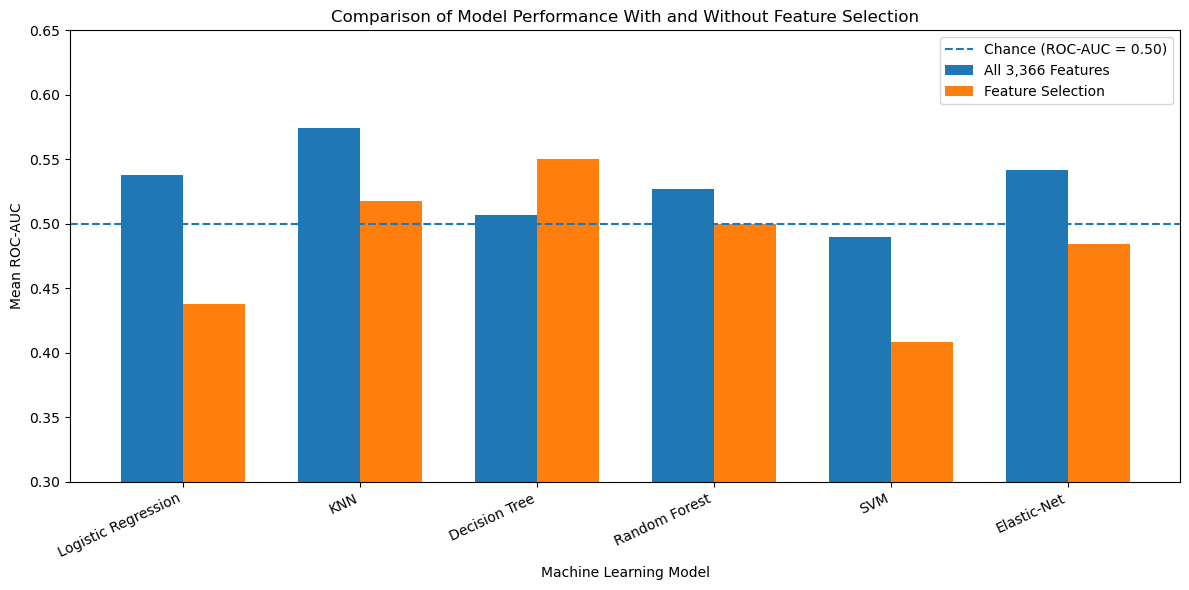

In [53]:
#feature selection vs all features 

models = [
    "Logistic Regression",
    "KNN",
    "Decision Tree",
    "Random Forest",
    "SVM",
    "Elastic-Net"
]

# Mean ROC-AUC values
all_features = [
    0.538,
    0.574,
    0.507,
    0.527,
    0.490,
    0.542
]

feature_selection = [
    0.438,
    0.518,
    0.550,
    0.500,
    0.408,
    0.484
]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(12, 6))

plt.bar(
    x - width/2,
    all_features,
    width,
    label="All 3,366 Features"
)

plt.bar(
    x + width/2,
    feature_selection,
    width,
    label="Feature Selection"
)

plt.axhline(
    0.5,
    linestyle="--",
    linewidth=1.5,
    label="Chance (ROC-AUC = 0.50)"
)

plt.ylabel("Mean ROC-AUC")
plt.xlabel("Machine Learning Model")
plt.title("Comparison of Model Performance With and Without Feature Selection")

plt.xticks(
    x,
    models,
    rotation=25,
    ha="right"
)

plt.ylim(0.3, 0.65)
plt.legend()
plt.tight_layout()

plt.savefig(
    "Feature_Selection_vs_All_Features_ROCAUC.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

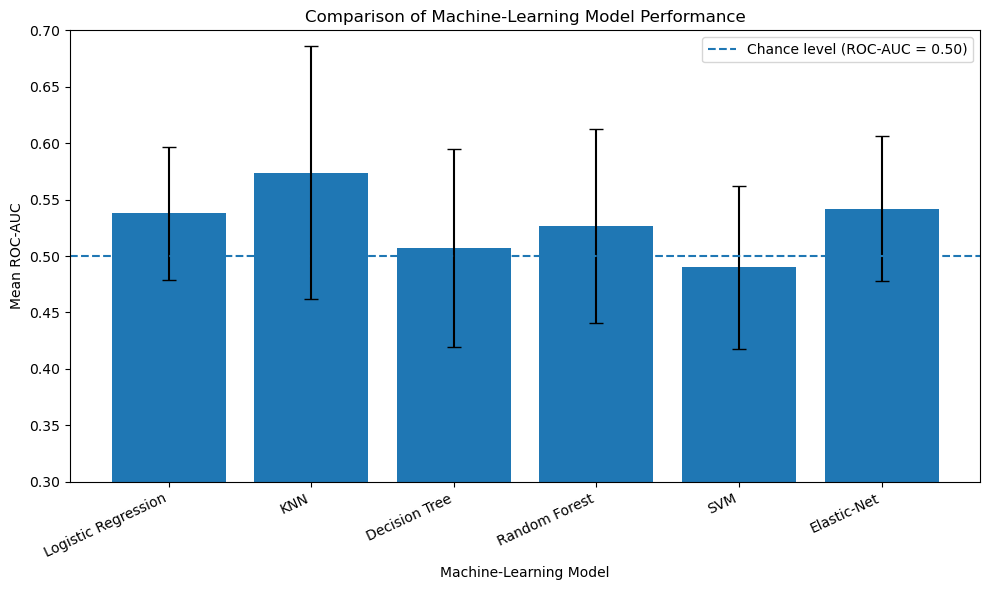

In [8]:
import matplotlib.pyplot as plt

models = [
    "Logistic Regression",
    "KNN",
    "Decision Tree",
    "Random Forest",
    "SVM",
    "Elastic-Net"
]

mean_auc = [
    0.538,
    0.574,
    0.507,
    0.527,
    0.490,
    0.542
]

std_auc = [
    0.059,
    0.112,
    0.088,
    0.086,
    0.072,
    0.064
]

plt.figure(figsize=(10, 6))

plt.bar(
    models,
    mean_auc,
    yerr=std_auc,
    capsize=5
)

plt.axhline(
    0.5,
    linestyle="--",
    linewidth=1.5,
    label="Chance level (ROC-AUC = 0.50)"
)

plt.ylabel("Mean ROC-AUC")
plt.xlabel("Machine-Learning Model")
plt.title("Comparison of Machine-Learning Model Performance")

plt.xticks(rotation=25, ha="right")
plt.ylim(0.3, 0.7)

plt.legend()
plt.tight_layout()

plt.savefig(
    "Six_Model_ROCAUC_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()